# Medicaid prescription spending: from dollars to review priorities

**Mohammed Mia | Healthcare Data Analytics | Python + SQL | 2024**

I built this analysis to understand where Medicaid prescription spending concentrates and which recorded product alternatives deserve closer price review. I follow five questions:

1. **Q1:** Which product NDCs account for the most spending?
2. **Q2:** Which pharmacologic categories are prominent?
3. **Q3:** Where do matched prices merit a savings review?
4. **Q4:** Which products have potentially comparable recorded alternatives?
5. **Q5:** How do geography, reporting period, and product category affect the spending picture?

The included extract covers **11 states and Washington, DC**, with **$27.54B in reported reimbursement before rebates**. Its findings do not represent a national spending estimate.

I start with the source CSVs and show the transformations, SQL, price calculations, and chart code below. Each section connects a question to a calculation and an interpretation. The final checks compare these calculations with the published pipeline results.

## 1. Import the tools and choose a chart style

I use pandas for tables, NumPy for numeric checks, and matplotlib for charts. `Path` locates the included data files. No custom project imports or prebuilt database are required.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams.update({
    "figure.figsize": (10, 5), "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 16, "axes.titleweight": "bold",
    "axes.labelsize": 11, "font.size": 10,
    "axes.prop_cycle": plt.cycler(color=["#168578", "#3974a8"]),
})
pd.set_option("display.max_columns", 12)

## 2. Load the two source files

I open the notebook from the `notebooks` folder or the repository root. The small path check supports either location. I read NDCs as text so their leading zeros survive.

One utilization record represents a utilization type, jurisdiction, package NDC, year, and quarter. The directory supplies product descriptions. The compressed CSVs are included in the repository.

In [2]:
project = Path(".")
if not (project / "data/raw").exists():
    project = Path("..")
assert (project / "data/raw/utilization.csv.gz").exists(), "Open the notebook inside the cloned repository."

source_columns = [
    "source_row", "Utilization Type", "State", "NDC", "Year", "Quarter",
    "Suppression Used", "Product Name", "Units Reimbursed",
    "Number of Prescriptions", "Medicaid Amount Reimbursed",
]
raw_utilization = pd.read_csv(project / "data/raw/utilization.csv.gz",
                              usecols=source_columns, dtype={"NDC": "string"})
raw_products = pd.read_csv(project / "data/raw/product_directory.csv.gz", dtype="string")
print(f"Utilization records: {len(raw_utilization):,}; product listings: {len(raw_products):,}")
display(raw_utilization.head())

Utilization records: 1,048,575; product listings: 113,878


,source_row,Utilization Type,State,NDC,Year,Quarter,Suppression Used,Product Name,Units Reimbursed,Number of Prescriptions,Medicaid Amount Reimbursed
0,2,MCOU,HI,00002015204,2024,4,1,ZEPBOUND 2,NaN,NaN,NaN
1,3,FFSU,AK,00002021301,2024,1,1,HUMULIN R,NaN,NaN,NaN
2,4,FFSU,AL,00002021301,2024,4,0,HUMULIN R,55.60,36.0,144.56
3,5,FFSU,AL,00002021301,2024,3,0,HUMULIN R,39.75,32.0,103.35
4,6,FFSU,AL,00002021301,2024,2,0,HUMULIN R,102.30,30.0,625.23


## 3. Prepare the utilization records

### Give the columns short, consistent names

I keep the original source-row number for traceability. Renaming changes labels, not the observations or values.

In [3]:
utilization = raw_utilization.rename(columns={
    "Utilization Type": "utilization_type", "State": "state", "NDC": "ndc11",
    "Year": "year", "Quarter": "quarter", "Suppression Used": "suppressed",
    "Product Name": "source_product_name", "Units Reimbursed": "units",
    "Number of Prescriptions": "prescriptions", "Medicaid Amount Reimbursed": "reimbursement",
}).copy()
for column in ["state", "utilization_type", "source_product_name", "ndc11"]:
    utilization[column] = utilization[column].astype("string").str.strip()
for column in ["year", "quarter", "units", "prescriptions", "reimbursement"]:
    utilization[column] = pd.to_numeric(utilization[column], errors="coerce")
del raw_utilization

### Standardize package NDCs and suppression flags

The source stores 11-character package NDCs. I remove any spreadsheet text-prefix apostrophe, verify the length, and take the first nine characters for the labeler/product key. I check suppression flags before using dollar amounts. Missing reimbursement remains unknown; I do not fill it with zero.

In [4]:
utilization["ndc11"] = utilization["ndc11"].str.replace("'", "", regex=False)
utilization["ndc_valid"] = utilization["ndc11"].str.fullmatch(r"\d{11}").fillna(False)
utilization["product_key"] = utilization["ndc11"].where(utilization["ndc_valid"]).str[:9]

suppression_text = utilization["suppressed"].astype("string").str.lower()
suppression_known = suppression_text.isin(["0", "1", "false", "true"])
utilization["suppressed"] = suppression_text.isin(["1", "true"])
display(utilization[["ndc11", "product_key", "suppressed", "reimbursement"]].head())

,ndc11,product_key,suppressed,reimbursement
0,00002015204,000020152,True,NaN
1,00002021301,000020213,True,NaN
2,00002021301,000020213,False,144.56
3,00002021301,000020213,False,103.35
4,00002021301,000020213,False,625.23


### Check jurisdiction codes and duplicate observations

I use a Census-style jurisdiction lookup to validate state codes and retain regional descriptors. The later comparison stays at jurisdiction level because the extract has limited geographic coverage. Duplicate checks include utilization type so managed-care and fee-for-service records are not mistaken for duplicates.

In [5]:
region_states = {
    "Northeast": "CT ME MA NH RI VT NJ NY PA",
    "Midwest": "IN IL MI OH WI IA KS MN MO NE ND SD",
    "South": "DE DC FL GA MD NC SC VA WV AL KY MS TN AR LA OK TX",
    "West": "AZ CO ID MT NV NM UT WY AK CA HI OR WA",
    "Territories": "AS GU MP PR VI",
}
state_to_region = {state: region for region, states in region_states.items() for state in states.split()}
utilization["region"] = utilization["state"].map(state_to_region).fillna("Unmapped")
observation_key = ["utilization_type", "state", "ndc11", "year", "quarter"]
utilization["duplicate_key"] = utilization.duplicated(observation_key, keep=False)
print(f"Rows sharing a duplicate observation key: {utilization['duplicate_key'].sum():,}")

Rows sharing a duplicate observation key: 0


### Decide which records support each calculation

Spending requires a valid reporting structure, a unique observation key, no suppression, and a reported nonnegative reimbursement. Price calculations also require positive units. I keep all rows for coverage reporting and use explicit flags to select the rows for each calculation.

In [6]:
valid_structure = (
    utilization["ndc_valid"] & suppression_known & utilization["year"].eq(2024)
    & utilization["quarter"].isin([1, 2, 3, 4])
    & utilization["utilization_type"].isin(["MCOU", "FFSU"])
    & utilization["state"].isin(state_to_region)
)
utilization["spend_eligible"] = (
    valid_structure & ~utilization["duplicate_key"] & ~utilization["suppressed"]
    & utilization["reimbursement"].notna() & utilization["reimbursement"].ge(0)
)
utilization["price_eligible"] = utilization["spend_eligible"] & utilization["units"].gt(0)
utilization["cost_per_unit"] = (
    utilization["reimbursement"] / utilization["units"].replace(0, np.nan)
).where(utilization["price_eligible"])

total_reimbursement = utilization.loc[utilization["spend_eligible"], "reimbursement"].sum()
print(f"Reported spending records: {utilization['spend_eligible'].sum():,}")
print(f"Suppressed records: {utilization['suppressed'].sum():,}")
print(f"Reported reimbursement: ${total_reimbursement:,.2f}")
print("Jurisdictions:", ", ".join(sorted(utilization["state"].dropna().unique())))

Reported spending records: 504,630
Suppressed records: 543,945
Reported reimbursement: $27,539,974,390.90
Jurisdictions: AK, AL, AR, AZ, CA, CO, CT, DC, DE, FL, GA, HI


I retain **504,630 spending records** and **543,945 suppressed records**. The spending total is **$27,539,974,390.90**. Suppression counts describe what is missing, but cannot reveal the dollars hidden by suppression.

## 4. Prepare the product directory and join it safely

### Normalize the directory's segmented NDCs

The directory supplies separate labeler and product segments. I validate their lengths, then pad each segment separately to five and four characters. Padding an entire ambiguous code would not establish where a missing zero belongs.

In [7]:
product_columns = {
    "PRODUCTNDC": "product_ndc", "PROPRIETARYNAME": "product_name",
    "NONPROPRIETARYNAME": "ingredient", "DOSAGEFORMNAME": "dosage_form", "ROUTENAME": "route",
    "ACTIVE_NUMERATOR_STRENGTH": "strength", "ACTIVE_INGRED_UNIT": "strength_unit",
    "MARKETINGCATEGORYNAME": "application_type", "PHARM_CLASSES": "pharm_classes",
    "STARTMARKETINGDATE": "marketing_start", "ENDMARKETINGDATE": "marketing_end",
    "LABELERNAME": "labeler", "PRODUCTTYPENAME": "product_type",
}
products_raw = raw_products[list(product_columns)].rename(columns=product_columns).copy()
segments = products_raw["product_ndc"].str.strip().str.extract(r"^(\d{4,5})-(\d{3,4})$")
products_raw["product_key"] = segments[0].str.zfill(5) + segments[1].str.zfill(4)
display(products_raw[["product_ndc", "product_key"]].head())
del raw_products

,product_ndc,product_key
0,0002-0152,000020152
1,0002-0213,000020213
2,0002-0243,000020243
3,0002-0800,000020800
4,0002-1152,000021152


### Standardize recorded formulation descriptions

I standardize whitespace and case while keeping salts, release forms, and ingredient order intact. I normalize purely numeric strength labels such as `10.0` to `10`. I do not reorder multi-ingredient strength strings or infer clinical equivalence from names.

In [8]:
formulation_columns = ["ingredient", "dosage_form", "route", "strength", "strength_unit"]
for column in formulation_columns:
    products_raw[column] = (products_raw[column].fillna("").str.strip()
                           .str.replace(r"\s+", " ", regex=True).str.casefold())
numeric_strength = products_raw["strength"].str.fullmatch(r"\d+(\.\d+)?")
products_raw.loc[numeric_strength, "strength"] = (
    products_raw.loc[numeric_strength, "strength"].astype(float).map(lambda value: format(value, ".12g"))
)
products_raw["application_type"] = products_raw["application_type"].fillna("Unknown").str.strip().str.upper()

### Resolve duplicate descriptions before joining

I collapse identical analytical descriptors. If one product key still has conflicting descriptions, I leave that key without attached metadata. I do not choose an arbitrary listing. This protects the join from multiplying observations and dollars.

In [9]:
descriptor_columns = [column for column in products_raw if column not in ["product_ndc", "product_key"]]
distinct_products = products_raw.drop_duplicates(["product_key"] + descriptor_columns)
conflicts = distinct_products.loc[
    distinct_products["product_key"].notna() & distinct_products.duplicated("product_key", keep=False)
].copy()
conflict_keys = conflicts["product_key"].unique()
directory = distinct_products.loc[
    distinct_products["product_key"].notna() & ~distinct_products["product_key"].isin(conflict_keys)
].copy()
print(f"Conflicting product keys left unmatched: {len(conflict_keys):,}")
print(f"Unambiguous product keys: {len(directory):,}")

Conflicting product keys left unmatched: 424
Unambiguous product keys: 112,284


In [10]:
joined = utilization.merge(directory, on="product_key", how="left", validate="many_to_one", indicator=True)
joined["metadata_matched"] = joined["_merge"].eq("both")
joined = joined.drop(columns="_merge")
assert len(joined) == len(utilization), "The join changed the observation count."
np.testing.assert_allclose(joined["reimbursement"].sum(), utilization["reimbursement"].sum(), rtol=0, atol=0.01)

spending = joined.loc[joined["spend_eligible"]].copy()
matched_dollars = spending.loc[spending["metadata_matched"], "reimbursement"].sum()
unmatched_dollars = spending.loc[~spending["metadata_matched"], "reimbursement"].sum()
print(f"Rows before / after join: {len(utilization):,} / {len(joined):,}")
print(f"Metadata coverage by dollars: {matched_dollars / total_reimbursement:.2%}")
print(f"Unmatched reimbursement retained: ${unmatched_dollars:,.2f}")

Rows before / after join: 1,048,575 / 1,048,575
Metadata coverage by dollars: 99.42%
Unmatched reimbursement retained: $160,852,518.29


Unambiguous descriptions cover **99.42% of reported dollars**. The remaining **$160.85M** stays in the spending denominator. A missing product description does not make its reported reimbursement disappear.

## Q1. Which products account for the most spending?

### Put the prepared observations into a local SQL table

I use SQLite, which is included with Python. The next cell creates a temporary in-memory database from the records prepared above. It does not call the pipeline or change its database. I select only the columns needed by the SQL analyses to keep this step smaller.

In [11]:
import sqlite3

connection = sqlite3.connect(":memory:")
sql_columns = [
    "product_key", "product_name", "source_product_name", "ingredient", "reimbursement",
    "spend_eligible", "state", "region", "suppressed", "quarter", "utilization_type",
    "ndc11", "metadata_matched", "prescriptions", "application_type",
]
joined[sql_columns].to_sql("utilization", connection, if_exists="replace", index=False, chunksize=10000)
assert connection.execute("SELECT COUNT(*) FROM utilization").fetchone()[0] == len(joined)
print("Prepared observations are ready for SQL analysis.")

Prepared observations are ready for SQL analysis.


### Aggregate products, then calculate their rank and share

The first SQL block totals reimbursement by product NDC. The second assigns ranks and uses window sums for individual and cumulative shares. The denominator includes products without attached metadata. A product NDC combines package sizes, not every strength of a brand.

In [12]:
product_query = """
WITH product_totals AS (
    SELECT product_key,
           COALESCE(MAX(product_name), MAX(source_product_name)) AS product_name,
           MAX(ingredient) AS ingredient, SUM(reimbursement) AS reimbursement,
           COUNT(*) AS records, COUNT(DISTINCT state) AS jurisdictions
    FROM utilization WHERE spend_eligible = 1 GROUP BY product_key
), ranked AS (
    SELECT *, ROW_NUMBER() OVER (ORDER BY reimbursement DESC, product_key) AS spend_rank,
           reimbursement / SUM(reimbursement) OVER () AS spend_share,
           SUM(reimbursement) OVER (ORDER BY reimbursement DESC, product_key
               ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW)
               / SUM(reimbursement) OVER () AS cumulative_share
    FROM product_totals
)
SELECT * FROM ranked ORDER BY spend_rank;
"""
products = pd.read_sql_query(product_query, connection)
product_view = products.head(10)[["product_key", "product_name", "reimbursement", "spend_share"]].copy()
product_view["reimbursement"] = product_view["reimbursement"].map("${:,.2f}".format)
product_view["spend_share"] = product_view["spend_share"].map("{:.2%}".format)
display(product_view)

,product_key,product_name,reimbursement,spend_share
0,619582501,Biktarvy,"$907,888,446.52",3.30%
1,000740554,Humira,"$633,429,714.83",2.30%
2,001694181,Ozempic,"$527,796,714.03",1.92%
3,001694130,Ozempic,"$404,945,247.57",1.47%
4,504580564,INVEGA SUSTENNA,"$397,690,422.18",1.44%
5,005970153,Jardiance,"$378,817,703.56",1.38%
6,000245915,Dupixent,"$346,782,739.48",1.26%
7,001694772,Ozempic,"$321,640,777.32",1.17%
8,578940061,STELARA,"$305,253,951.05",1.11%
9,005970152,Jardiance,"$290,855,662.37",1.06%


### Plot the highest-spending products

I plot the top ten product totals in millions of dollars. The labels retain product keys so separate strengths of a brand remain distinguishable.

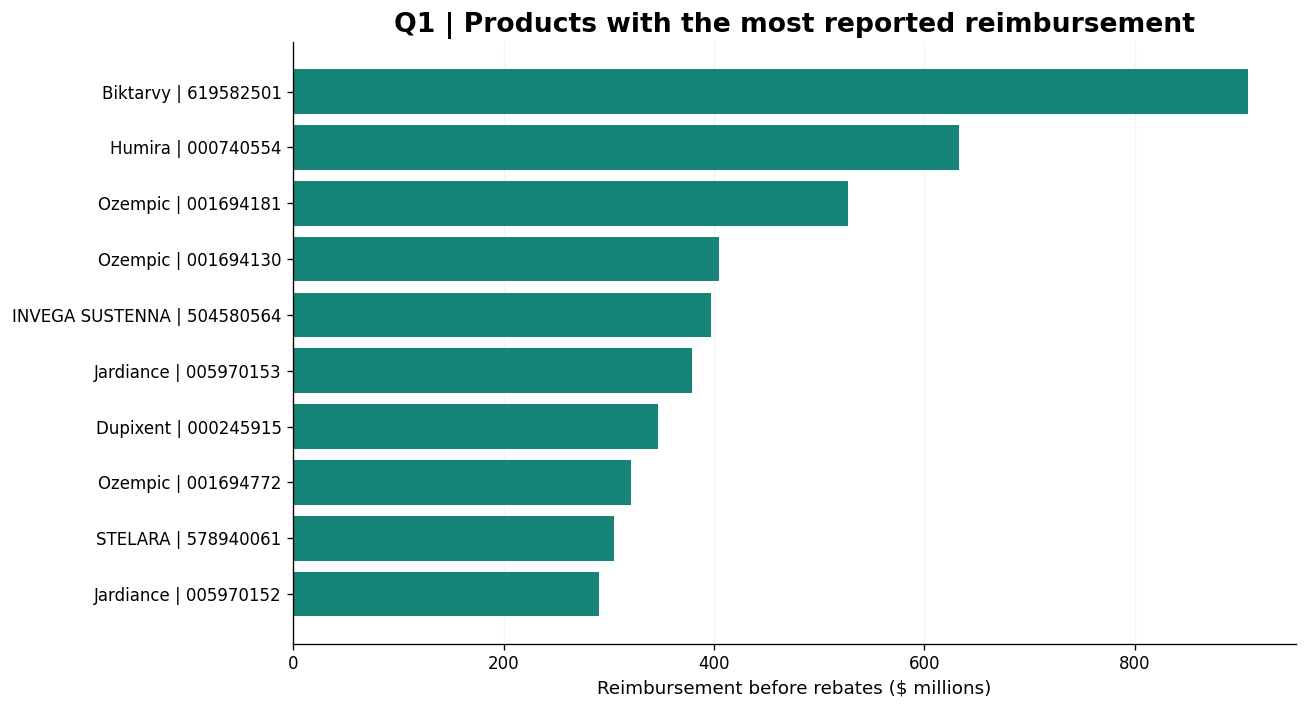

In [13]:
top_products = products.head(10).iloc[::-1]
labels = top_products["product_name"] + " | " + top_products["product_key"]
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(labels, top_products["reimbursement"] / 1e6, color="#168578")
ax.set(title="Q1 | Products with the most reported reimbursement",
       xlabel="Reimbursement before rebates ($ millions)")
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

Top 10 product NDCs: 16.4% of reported reimbursement
Top 50 product NDCs: 37.1% of reported reimbursement
Top 100 product NDCs: 49.5% of reported reimbursement


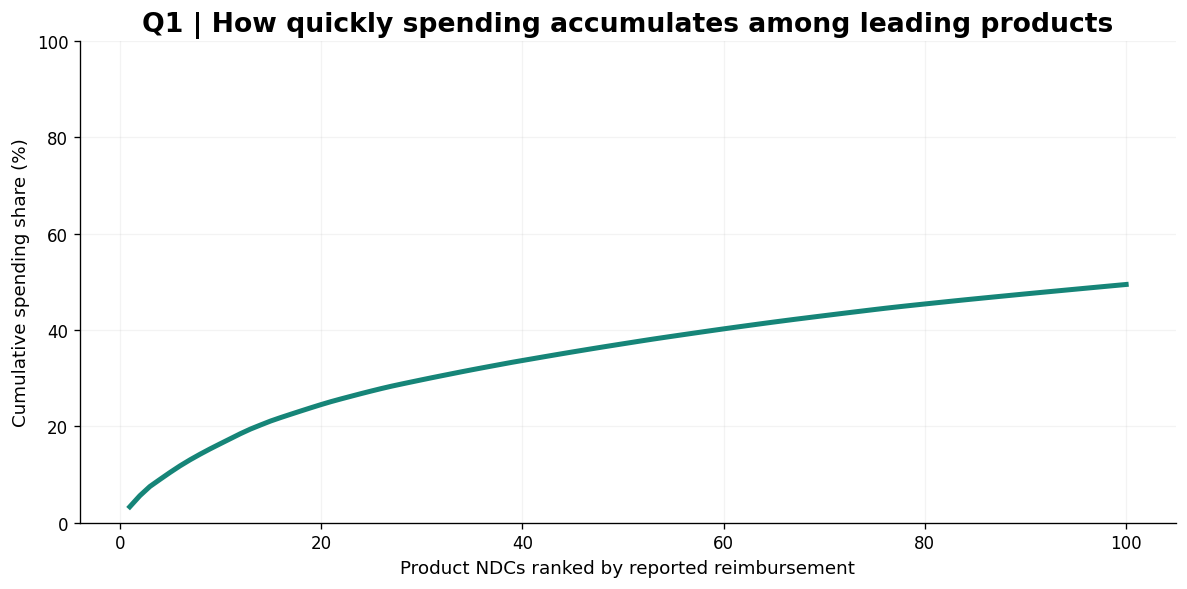

In [14]:
for count in [10, 50, 100]:
    share = products.head(count)["spend_share"].sum()
    print(f"Top {count} product NDCs: {share:.1%} of reported reimbursement")

fig, ax = plt.subplots()
ax.plot(products.head(100)["spend_rank"], products.head(100)["cumulative_share"] * 100, linewidth=3)
ax.set(title="Q1 | How quickly spending accumulates among leading products",
       xlabel="Product NDCs ranked by reported reimbursement", ylabel="Cumulative spending share (%)",
       ylim=(0, 100))
ax.grid(alpha=0.15)
fig.tight_layout()
plt.show()

**What I learned:** Biktarvy product NDC **619582501** accounts for **$907.89M**. The top 50 product NDCs account for **37.1%** of reimbursement. I would begin detailed review with this concentrated product set. The ranking establishes dollar exposure, not whether the spending is wasteful.

## Q2. Which pharmacologic categories are prominent?

### Extract the recorded EPC tags and summarize their dollars

I extract labels marked `[EPC]`, remove repeated raw tags within each record, and retain an explicit group when no EPC tag is available. `explode` makes one row per record/tag pair. A combination product can contribute to several tags, so these totals overlap and must not be added together.

In [15]:
tagged = spending[["source_row", "reimbursement", "pharm_classes"]].copy()
raw_tags = tagged["pharm_classes"].fillna("").str.findall(r"([^,]+?)\s*\[EPC\]")
tagged["epc_tag"] = raw_tags.map(
    lambda tags: [tag.strip() for tag in sorted(set(tags))] or ["No recorded EPC tag / unmatched"]
)
classes = tagged.explode("epc_tag").groupby("epc_tag").agg(
    tagged_reimbursement=("reimbursement", "sum"), tagged_records=("source_row", "size")
).sort_values("tagged_reimbursement", ascending=False).reset_index()
classes["interpretation"] = "Overlapping source tags; tagged amounts must not be added across classes"
class_view = classes.head(9)[["epc_tag", "tagged_reimbursement"]].copy()
class_view["tagged_reimbursement"] = class_view["tagged_reimbursement"].map("${:,.2f}".format)
display(class_view)
del tagged, raw_tags

,epc_tag,tagged_reimbursement
0,No recorded EPC tag / unmatched,"$5,185,279,274.11"
1,GLP-1 Receptor Agonist,"$2,941,561,694.62"
2,Hepatitis B Virus Nucleoside Analog Reverse Tr...,"$1,578,066,682.15"
3,Human Immunodeficiency Virus Nucleoside Analog...,"$1,573,086,030.26"
4,Atypical Antipsychotic,"$1,433,197,789.78"
5,Sodium-Glucose Cotransporter 2 Inhibitor,"$1,015,112,071.88"
6,Corticosteroid,"$924,176,432.08"
7,Kinase Inhibitor,"$820,472,145.95"
8,Interleukin-23 Antagonist,"$797,153,846.35"


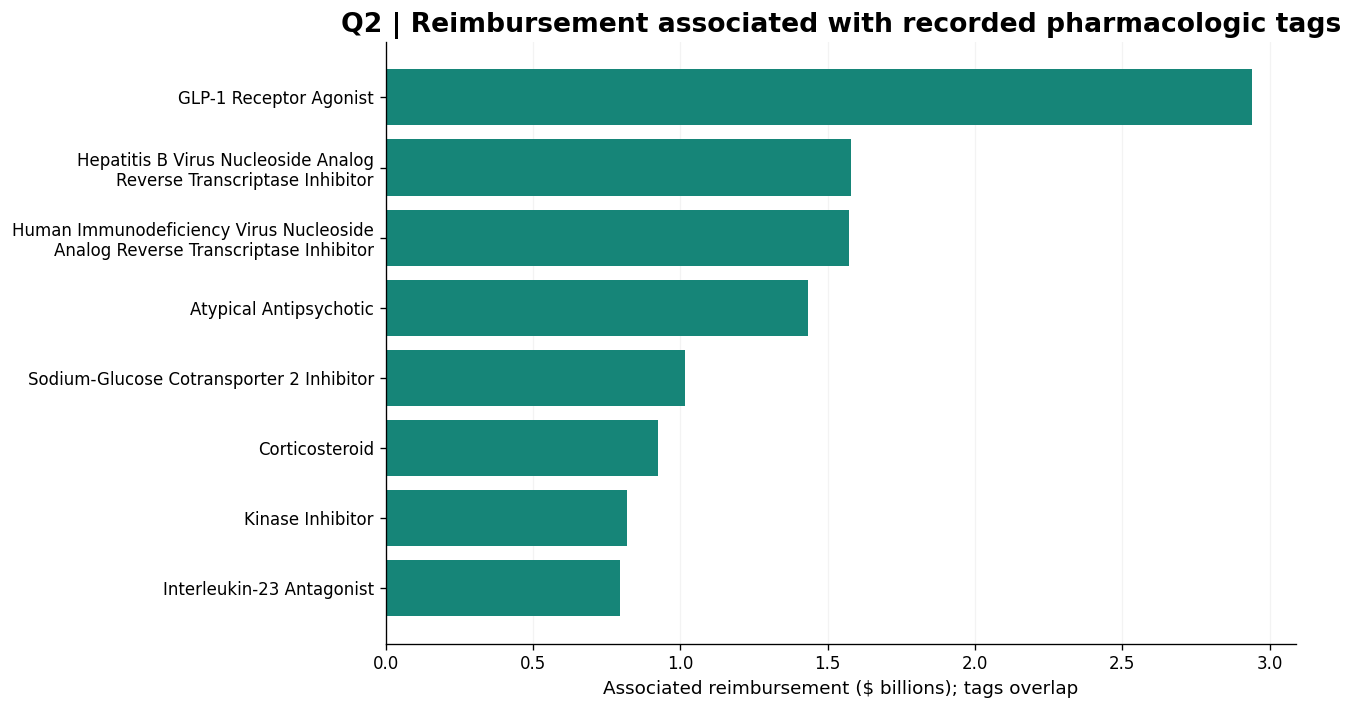

In [16]:
from textwrap import fill

class_chart = classes.loc[classes["epc_tag"].ne("No recorded EPC tag / unmatched")].head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh([fill(tag, 42) for tag in class_chart["epc_tag"]],
        class_chart["tagged_reimbursement"] / 1e9, color="#168578")
ax.set(title="Q2 | Reimbursement associated with recorded pharmacologic tags",
       xlabel="Associated reimbursement ($ billions); tags overlap")
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

**What I learned:** products carrying the GLP-1 Receptor Agonist tag account for **$2.94B**. HIV-related reverse transcriptase inhibitors, atypical antipsychotics, and SGLT2 inhibitors also appear prominently. These tags help organize the product review. I keep **$5.19B** without a recorded EPC tag or with unmatched metadata in the overall spending picture.

## Q3. Where do matched prices merit a savings review?

### Define what must match

I require the same ingredient, dosage form, route, strength, and strength unit. I also match jurisdiction, quarter, and utilization type. This keeps prices from different reporting settings out of the same comparison. I compare NDA- and ANDA-listed prescription products; these application categories are not a complete brand/generic classification.

In [17]:
formulation_columns = ["ingredient", "dosage_form", "route", "strength", "strength_unit"]
match_columns = formulation_columns + ["state", "quarter", "utilization_type"]
complete_descriptors = joined[formulation_columns].fillna("").ne("").all(axis=1)
quarter_start = joined["quarter"].map({1: 20240101, 2: 20240401, 3: 20240701, 4: 20241001})
quarter_end = joined["quarter"].map({1: 20240331, 2: 20240630, 3: 20240930, 4: 20241231})
marketing_start = pd.to_numeric(joined["marketing_start"], errors="coerce")
marketing_end = pd.to_numeric(joined["marketing_end"], errors="coerce")
marketing_overlap = (
    marketing_start.notna() & marketing_start.le(quarter_end)
    & (marketing_end.isna() | marketing_end.ge(quarter_start))
)

### Select records eligible for price comparison

The marketing-date check requires a known start date no later than quarter end. A recorded end date must not precede quarter start. This checks date overlap, not whether the directory is a historical 2024 snapshot.

In [18]:
screen_eligible = (
    joined["price_eligible"] & joined["metadata_matched"] & complete_descriptors
    & joined["application_type"].isin(["NDA", "ANDA"])
    & joined["product_type"].eq("HUMAN PRESCRIPTION DRUG") & marketing_overlap
)
price_sample = joined.loc[screen_eligible]
print(f"Records eligible for the price screen: {len(price_sample):,}")

Records eligible for the price screen: 426,222


### Add dollars and units before calculating prices

My question concerns observed dollars at observed utilization. I therefore calculate **total reimbursement divided by total units** within each group. This is the unit-weighted price: a small and a large record do not receive equal influence. A median instead describes the middle row-level price.

In [19]:
group_totals = price_sample.groupby(match_columns + ["application_type"], observed=True).agg(
    reimbursement=("reimbursement", "sum"), units=("units", "sum"),
    records=("source_row", "size"), products=("product_key", "nunique"),
).reset_index()
display(group_totals.head())

,ingredient,dosage_form,route,strength,strength_unit,state,...,utilization_type,application_type,reimbursement,units,records,products
0,0.12% chlorhexidine gluconate,rinse,oral,1.2,mg/ml,CA,...,FFSU,ANDA,264.87,101.0,1,1
1,0.12% chlorhexidine gluconate,rinse,oral,1.2,mg/ml,CA,...,FFSU,ANDA,1019.48,542.0,1,1
2,0.12% chlorhexidine gluconate,rinse,oral,1.2,mg/ml,CA,...,FFSU,ANDA,410.52,143.0,1,1
3,0.12% chlorhexidine gluconate,rinse,oral,1.2,mg/ml,CA,...,FFSU,ANDA,264.90,123.0,1,1
4,abacavir,tablet,oral,300,mg/1,CA,...,FFSU,ANDA,1557.21,1950.0,1,1


### Place the NDA and ANDA observations side by side

I make one table for each application category and use an inner join on the complete matching key. Only reporting groups observed on both sides survive. The one-to-one validation prevents an accidental multiplication of comparison rows.

In [20]:
nda = group_totals.loc[group_totals["application_type"].eq("NDA")].drop(columns="application_type")
anda = group_totals.loc[group_totals["application_type"].eq("ANDA")].drop(columns="application_type")
gaps = nda.merge(anda, on=match_columns, how="inner", suffixes=("_nda", "_anda"), validate="one_to_one")
print(f"Matched reporting groups: {len(gaps):,}")
print(f"Distinct recorded formulations: {len(gaps[formulation_columns].drop_duplicates()):,}")

Matched reporting groups: 6,675
Distinct recorded formulations: 562


### Calculate weighted prices and gross differences

I multiply the price difference by observed NDA units. For example, 100 units at a $10 NDA price compared with a $2 ANDA price gives an $800 signed difference. That example illustrates the arithmetic; it does not establish substitution feasibility.

I preserve negative differences and separately calculate the positive amount for prioritization.

In [21]:
gaps["nda_weighted_cpu"] = gaps["reimbursement_nda"] / gaps["units_nda"]
gaps["anda_weighted_cpu"] = gaps["reimbursement_anda"] / gaps["units_anda"]
gaps["signed_gap_per_unit"] = gaps["nda_weighted_cpu"] - gaps["anda_weighted_cpu"]
gaps["signed_gross_gap"] = gaps["signed_gap_per_unit"] * gaps["units_nda"]
gaps["positive_gross_gap"] = gaps["signed_gross_gap"].clip(lower=0)
gaps["gap_share_of_nda_reimbursement"] = (
    gaps["positive_gross_gap"] / gaps["reimbursement_nda"].replace(0, np.nan)
)
gaps = gaps.sort_values("positive_gross_gap", ascending=False).reset_index(drop=True)
positive_gap = gaps["positive_gross_gap"].sum()
signed_gap = gaps["signed_gross_gap"].sum()
print(f"Positive gross reimbursement gap: ${positive_gap:,.2f}")
print(f"Signed gross gap, including negative differences: ${signed_gap:,.2f}")

Positive gross reimbursement gap: $516,161,761.37
Signed gross gap, including negative differences: $506,733,293.57


### Rank formulations across their reporting groups

I aggregate the positive and signed amounts separately. Positive gaps are clipped at zero **before** this aggregation. A formulation can therefore have a positive review gap even when its signed aggregate is negative. I keep both columns visible.

In [22]:
formulations = gaps.groupby(formulation_columns).agg(
    positive_gross_gap=("positive_gross_gap", "sum"), signed_gross_gap=("signed_gross_gap", "sum"),
    nda_reimbursement=("reimbursement_nda", "sum"), nda_units=("units_nda", "sum"),
    paired_strata=("state", "size"), jurisdictions=("state", "nunique"),
).sort_values("positive_gross_gap", ascending=False).reset_index()
formulation_view = formulations.head(5)[formulation_columns + ["positive_gross_gap", "signed_gross_gap"]].copy()
for column in ["positive_gross_gap", "signed_gross_gap"]:
    formulation_view[column] = formulation_view[column].map("${:,.2f}".format)
display(formulation_view)

,ingredient,dosage_form,route,strength,strength_unit,positive_gross_gap,signed_gross_gap
0,cyclosporine,emulsion,ophthalmic,0.5,mg/ml,"$44,502,055.24","$44,502,055.24"
1,lisdexamfetamine dimesylate,capsule,oral,30,mg/1,"$22,828,194.45","$22,828,194.45"
2,methylphenidate hydrochloride,"tablet, extended release",oral,36,mg/1,"$22,337,014.96","$22,337,014.96"
3,lisdexamfetamine dimesylate,capsule,oral,40,mg/1,"$19,214,783.26","$19,214,783.26"
4,fluticasone propionate and salmeterol,powder,respiratory (inhalation),250; 50,ug/1; ug/1,"$19,047,676.27","$19,045,894.81"


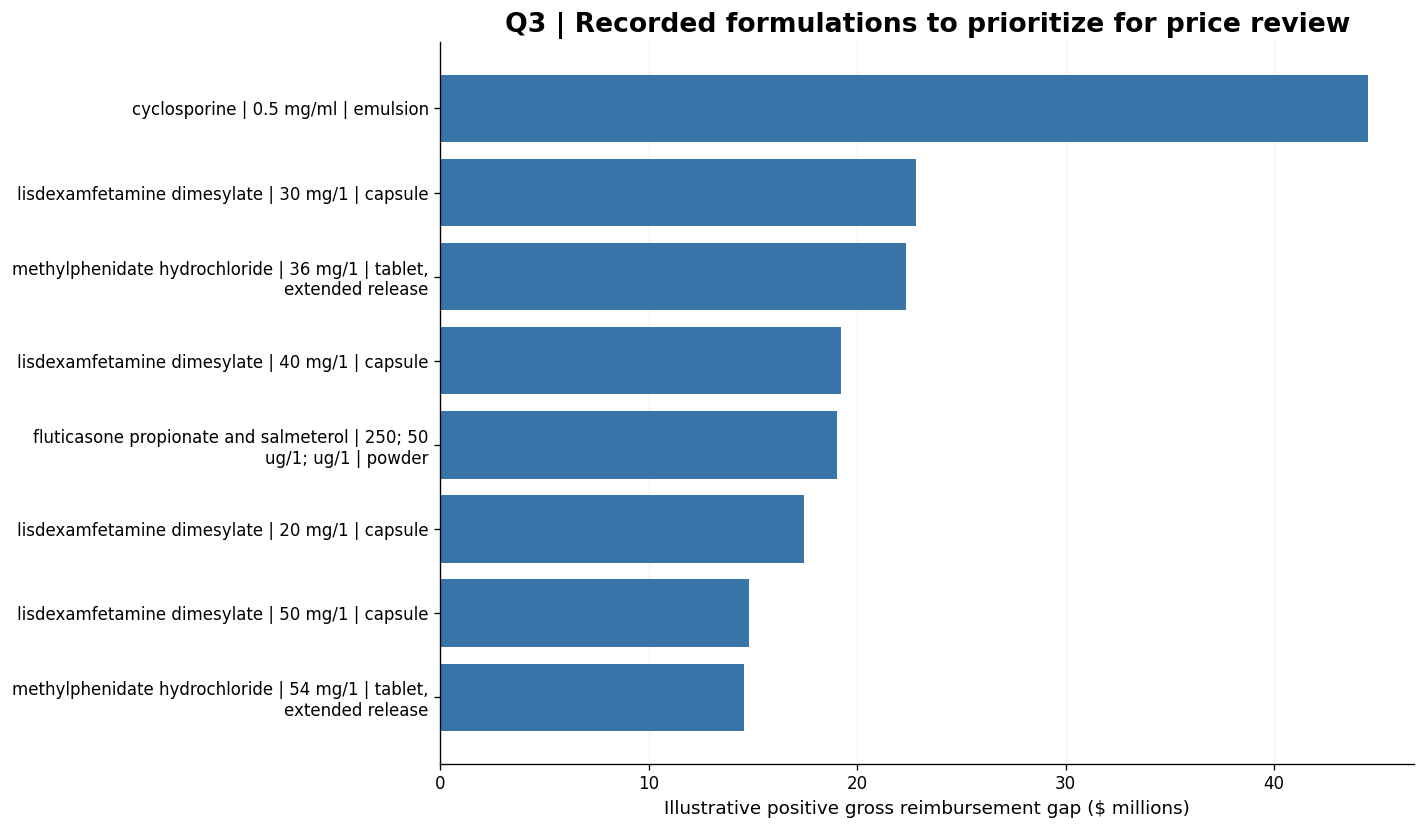

In [23]:
gap_chart = formulations.head(8).iloc[::-1]
labels = [fill(f"{row.ingredient} | {row.strength} {row.strength_unit} | {row.dosage_form}", 52)
          for row in gap_chart.itertuples()]
fig, ax = plt.subplots(figsize=(12, 7))
ax.barh(labels, gap_chart["positive_gross_gap"] / 1e6, color="#3974a8")
ax.set(title="Q3 | Recorded formulations to prioritize for price review",
       xlabel="Illustrative positive gross reimbursement gap ($ millions)")
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

**What I learned:** **562 formulations** appear in **6,675 matched reporting groups**. Positive differences sum to **$516.16M**; the signed aggregate is **$506.73M**. These results identify candidates for investigation. Missing unit-type, rebate, equivalence, and feasibility information prevents me from interpreting the gap as achievable or net savings.

### Show arithmetic scaling without estimating adoption

I multiply the positive aggregate by four illustrative fractions. These are mechanical scenarios, not predicted or clinically feasible substitution rates.

In [24]:
scenarios = pd.DataFrame({"hypothetical_fraction": [0.25, 0.50, 0.75, 1.00]})
scenarios["illustrative_gross_gap"] = scenarios["hypothetical_fraction"] * positive_gap
scenarios["interpretation"] = "Mechanical sensitivity only; not feasible substitution or net budget savings"
scenario_view = scenarios[["hypothetical_fraction", "illustrative_gross_gap"]].copy()
scenario_view["hypothetical_fraction"] = scenario_view["hypothetical_fraction"].map("{:.0%}".format)
scenario_view["illustrative_gross_gap"] = scenario_view["illustrative_gross_gap"].map("${:,.2f}".format)
display(scenario_view)

,hypothetical_fraction,illustrative_gross_gap
0,25%,"$129,040,440.34"
1,50%,"$258,080,880.68"
2,75%,"$387,121,321.03"
3,100%,"$516,161,761.37"


## Q4. Which products have potentially comparable recorded alternatives?

I inspect the actual matching descriptors alongside the dollar exposure. The table above is a review list, not a clinical substitution list. The following example makes its analytical unit explicit.

In [25]:
candidate = formulations.iloc[0]
print(f"Ingredient: {candidate['ingredient']}")
print(f"Strength: {candidate['strength']} {candidate['strength_unit']}")
print(f"Form: {candidate['dosage_form']}; route: {candidate['route']}")
print(f"Positive gross gap: ${candidate['positive_gross_gap'] / 1e6:.2f}M")
print(f"Matched groups: {candidate['paired_strata']}; jurisdictions: {candidate['jurisdictions']}")

Ingredient: cyclosporine
Strength: 0.5 mg/ml
Form: emulsion; route: ophthalmic
Positive gross gap: $44.50M
Matched groups: 10; jurisdictions: 3


**What I learned:** cyclosporine **0.5 mg/mL ophthalmic emulsion** has a **$44.50M** positive gross gap. The result concerns that specific formulation, not every cyclosporine product. Other leading candidates include lisdexamfetamine dimesylate **30 mg oral capsules** ($22.83M) and methylphenidate hydrochloride **36 mg oral extended-release tablets** ($22.34M).

Before acting, I would verify the reimbursement-unit basis, applicable therapeutic-equivalence evidence, practical availability, patient suitability, and net rebate economics. A matching recorded description does not establish all of those conditions.

## Q5. How do geography and reporting context affect the spending picture?

### Compare jurisdiction totals alongside suppression

I count all source observations for coverage, but sum only eligible reimbursement. The `CASE` expressions select known eligible dollars; they do not impute the unknown suppressed amounts. I also retain the share of known dollars with attached metadata.

In [26]:
coverage_query = """
SELECT state, MAX(region) AS region, COUNT(*) AS source_records,
       SUM(suppressed) AS suppressed_records,
       1.0 * SUM(suppressed) / COUNT(*) AS suppressed_record_share,
       SUM(spend_eligible) AS spend_eligible_records,
       COUNT(DISTINCT quarter) AS observed_quarters,
       COUNT(DISTINCT utilization_type) AS observed_utilization_types,
       COUNT(DISTINCT ndc11) AS observed_package_ndcs,
       SUM(CASE WHEN spend_eligible = 1 THEN reimbursement ELSE 0 END) AS reimbursement,
       SUM(CASE WHEN spend_eligible = 1 AND metadata_matched = 1 THEN reimbursement ELSE 0 END)
           / NULLIF(SUM(CASE WHEN spend_eligible = 1 THEN reimbursement ELSE 0 END), 0)
           AS metadata_matched_spend_share
FROM utilization GROUP BY state ORDER BY reimbursement DESC;
"""
coverage = pd.read_sql_query(coverage_query, connection)
coverage_view = coverage[["state", "source_records", "suppressed_record_share", "reimbursement"]].copy()
coverage_view["suppressed_record_share"] = coverage_view["suppressed_record_share"].map("{:.1%}".format)
coverage_view["reimbursement"] = coverage_view["reimbursement"].map("${:,.2f}".format)
display(coverage_view)

,state,source_records,suppressed_record_share,reimbursement
0,CA,160323,39.4%,"$15,554,455,823.62"
1,FL,124606,49.7%,"$3,164,140,633.14"
2,CT,71030,46.4%,"$1,920,175,015.75"
3,AZ,95905,53.0%,"$1,849,963,296.01"
4,CO,95583,54.2%,"$1,453,885,229.54"
5,GA,127780,48.9%,"$1,241,096,254.38"
6,AL,68739,47.2%,"$1,000,427,325.06"
7,AR,90130,54.6%,"$458,001,525.46"
8,DC,74971,72.5%,"$246,927,083.94"
9,DE,59686,63.8%,"$240,478,503.41"


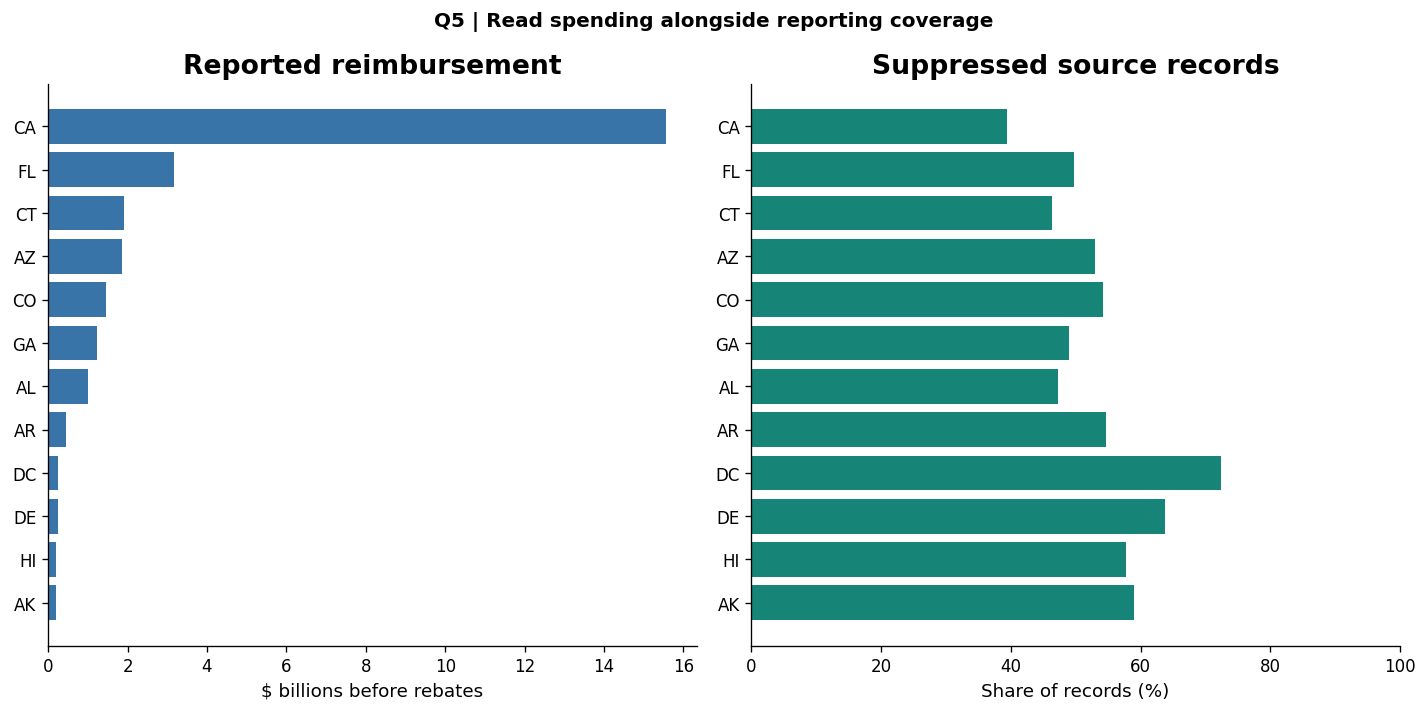

California share of reported reimbursement: 56.5%


In [27]:
coverage_chart = coverage.iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].barh(coverage_chart["state"], coverage_chart["reimbursement"] / 1e9, color="#3974a8")
axes[0].set(title="Reported reimbursement", xlabel="$ billions before rebates")
axes[1].barh(coverage_chart["state"], coverage_chart["suppressed_record_share"] * 100, color="#168578")
axes[1].set(title="Suppressed source records", xlabel="Share of records (%)", xlim=(0, 100))
fig.suptitle("Q5 | Read spending alongside reporting coverage", fontweight="bold")
fig.tight_layout()
plt.show()

california_share = coverage.loc[coverage["state"].eq("CA"), "reimbursement"].sum() / total_reimbursement
print(f"California share of reported reimbursement: {california_share:.1%}")

California contributes **56.5%** of this extract's reimbursement. This is an absolute spending share. It does not establish higher prices or lower efficiency: enrollment, patient and drug mix, utilization, and completeness are not controlled. Suppressed record share is not the share of dollars missing.

### Describe quarterly changes with SQL LAG

I calculate reimbursement per reported prescription and compare each quarter with the preceding quarter. These are descriptive changes within the extract, not estimated policy effects.

In [28]:
quarter_query = """
WITH quarterly AS (
    SELECT quarter, SUM(reimbursement) AS reimbursement,
           COUNT(*) AS spend_eligible_records, SUM(prescriptions) AS prescriptions
    FROM utilization WHERE spend_eligible = 1 GROUP BY quarter
)
SELECT *, reimbursement / NULLIF(prescriptions, 0) AS reimbursement_per_prescription,
       reimbursement / LAG(reimbursement) OVER (ORDER BY quarter) - 1 AS quarter_change
FROM quarterly ORDER BY quarter;
"""
quarters = pd.read_sql_query(quarter_query, connection)
quarter_view = quarters[["quarter", "reimbursement", "reimbursement_per_prescription", "quarter_change"]].copy()
for column in ["reimbursement", "reimbursement_per_prescription"]:
    quarter_view[column] = quarter_view[column].map("${:,.2f}".format)
quarter_view["quarter_change"] = quarter_view["quarter_change"].map(lambda value: "--" if pd.isna(value) else f"{value:+.1%}")
display(quarter_view)

,quarter,reimbursement,reimbursement_per_prescription,quarter_change
0,1,"$6,700,734,254.80",$145.91,--
1,2,"$6,364,889,546.97",$150.47,-5.0%
2,3,"$7,629,746,295.33",$163.21,+19.9%
3,4,"$6,844,604,293.80",$159.33,-10.3%


### Summarize spending by recorded application category

I retain unmatched metadata as an explicit category. NDA, BLA, and ANDA are directory application categories, not a definitive brand/generic classification.

In [29]:
application_query = """
SELECT COALESCE(application_type, 'Unmatched') AS application_type,
       SUM(reimbursement) AS reimbursement, COUNT(*) AS records,
       SUM(reimbursement) / (SELECT SUM(reimbursement) FROM utilization WHERE spend_eligible = 1)
           AS spend_share
FROM utilization WHERE spend_eligible = 1
GROUP BY COALESCE(application_type, 'Unmatched') ORDER BY reimbursement DESC;
"""
applications = pd.read_sql_query(application_query, connection)
application_view = applications[["application_type", "reimbursement", "spend_share"]].copy()
application_view["reimbursement"] = application_view["reimbursement"].map("${:,.2f}".format)
application_view["spend_share"] = application_view["spend_share"].map("{:.1%}".format)
display(application_view)
connection.close()

,application_type,reimbursement,spend_share
0,NDA,"$15,997,676,549.40",58.1%
1,BLA,"$7,931,433,481.80",28.8%
2,ANDA,"$2,844,980,842.35",10.3%
3,NDA AUTHORIZED GENERIC,"$510,830,868.27",1.9%
4,Unmatched,"$160,852,518.29",0.6%
5,OTC MONOGRAPH DRUG,"$51,353,982.61",0.2%
6,UNAPPROVED DRUG OTHER,"$41,630,513.38",0.2%
7,EMERGENCY USE AUTHORIZATION,"$977,667.17",0.0%
8,OTC MONOGRAPH NOT FINAL,"$171,506.17",0.0%
9,OTC MONOGRAPH FINAL,"$52,471.26",0.0%


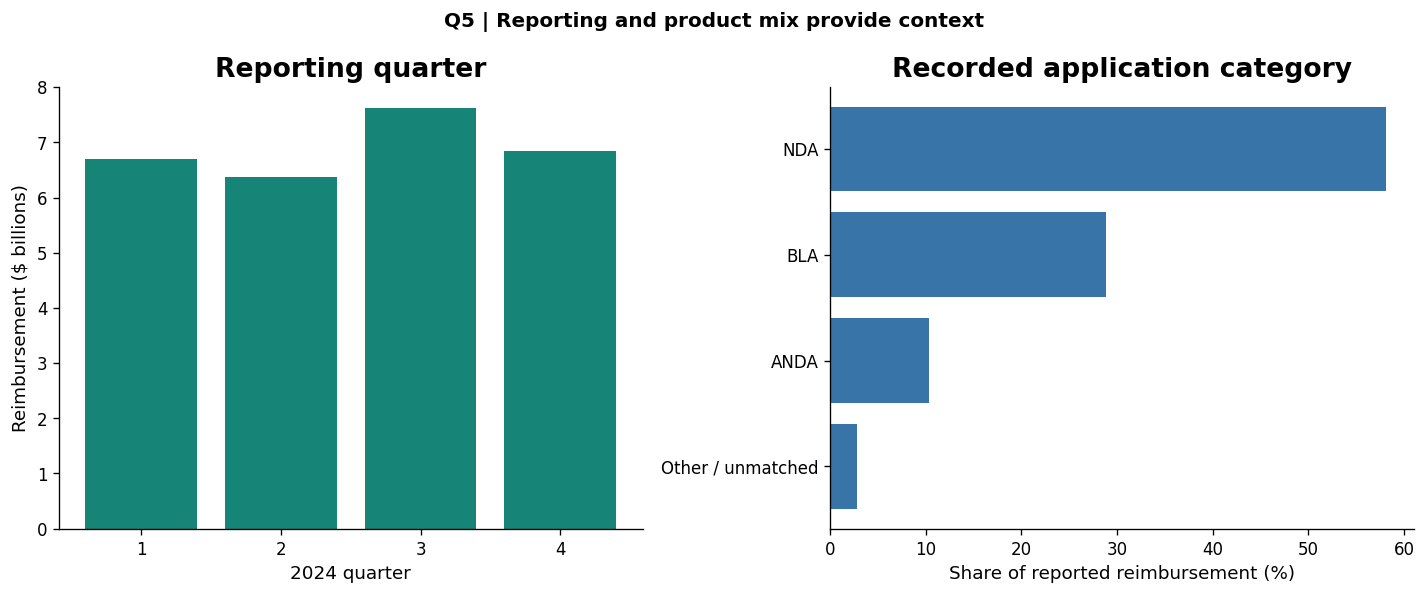

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].bar(quarters["quarter"], quarters["reimbursement"] / 1e9, color="#168578")
axes[0].set(title="Reporting quarter", xlabel="2024 quarter", ylabel="Reimbursement ($ billions)",
            xticks=[1, 2, 3, 4])
category_labels = applications.head(3)["application_type"].tolist() + ["Other / unmatched"]
category_shares = applications.head(3)["spend_share"].tolist() + [1 - applications.head(3)["spend_share"].sum()]
axes[1].barh(category_labels[::-1], np.array(category_shares[::-1]) * 100, color="#3974a8")
axes[1].set(title="Recorded application category", xlabel="Share of reported reimbursement (%)")
fig.suptitle("Q5 | Reporting and product mix provide context", fontweight="bold")
fig.tight_layout()
plt.show()

**What I learned:** Q3 has the highest reported reimbursement at **$7.63B**. NDA, BLA, and ANDA listings account for **58.1%**, **28.8%**, and **10.3%** of spending. These are distributions, not evidence of causal drivers. I keep geographic comparisons at jurisdiction level because only 11 states and DC are represented.

## 5. Check that the visible calculations preserve the published results

The pipeline remains available for repeatable batch processing. I independently calculated the notebook results from source records above. Only now do I load the published tables to compare them with those calculations.

### Compare every row of the nine result tables

The small comparison helper aligns rows by their actual keys, preserves text identifiers, and compares numeric values within floating-point tolerance. Dollar amounts must agree within one cent, with a very small relative tolerance for large values. It does not calculate analytical results.

In [31]:
def check_table(actual, filename, keys):
    expected = pd.read_csv(project / "reports/tables" / filename, dtype={
        "product_key": "string", "strength": "string", "marketing_start": "string", "marketing_end": "string",
    })
    left = actual[expected.columns].sort_values(keys).reset_index(drop=True).copy()
    right = expected.sort_values(keys).reset_index(drop=True).copy()
    for column in right.columns:
        if not pd.api.types.is_numeric_dtype(right[column]):
            left[column] = left[column].astype("string").fillna("")
            right[column] = right[column].astype("string").fillna("")
    pd.testing.assert_frame_equal(left, right, check_dtype=False, check_exact=False, rtol=1e-12, atol=1e-8)
    for column in ["reimbursement", "tagged_reimbursement", "positive_gross_gap", "signed_gross_gap",
                   "nda_reimbursement", "reimbursement_nda", "reimbursement_anda", "illustrative_gross_gap"]:
        if column in right:
            np.testing.assert_allclose(left[column], right[column], rtol=0, atol=0.01)
    print(f"PASS: {filename} ({len(left):,} rows)")

check_table(products, "product_spending.csv", ["product_key"])
check_table(coverage, "jurisdiction_coverage.csv", ["state"])
check_table(quarters, "quarterly_spending.csv", ["quarter"])
check_table(applications, "application_spending.csv", ["application_type"])
check_table(classes, "epc_tag_spending.csv", ["epc_tag"])
check_table(gaps, "formulation_strata_gaps.csv.gz", match_columns)
check_table(formulations, "formulation_gap_ranking.csv", formulation_columns)
check_table(scenarios, "illustrative_scenarios.csv", ["hypothetical_fraction"])
check_table(conflicts, "directory_conflicts.csv", ["product_key"] + descriptor_columns)

PASS: product_spending.csv (19,101 rows)
PASS: jurisdiction_coverage.csv (12 rows)
PASS: quarterly_spending.csv (4 rows)
PASS: application_spending.csv (11 rows)
PASS: epc_tag_spending.csv (480 rows)
PASS: formulation_strata_gaps.csv.gz (6,675 rows)
PASS: formulation_gap_ranking.csv (562 rows)
PASS: illustrative_scenarios.csv (4 rows)
PASS: directory_conflicts.csv (882 rows)


### Reconcile totals, source files, and matching bounds

I require the spending views to reconcile to the same denominator. I also verify the source checksums, baseline counts, matched-group uniqueness, and the bound that a positive gross gap cannot exceed its observed NDA reimbursement.

In [32]:
import hashlib
import json

summary = json.loads((project / "reports/analysis_summary.json").read_text())
for filename, expected_hash in summary["input_sha256"].items():
    with (project / "data/raw" / filename).open("rb") as source:
        assert hashlib.file_digest(source, "sha256").hexdigest() == expected_hash
for table in [products, coverage, quarters, applications]:
    np.testing.assert_allclose(table["reimbursement"].sum(), total_reimbursement, rtol=0, atol=0.01)
assert len(utilization) == summary["utilization"]["source_records"]
assert utilization["spend_eligible"].sum() == summary["utilization"]["spend_eligible_records"]
assert utilization["suppressed"].sum() == summary["utilization"]["suppressed_records"]
assert len(price_sample) == summary["reimbursement_gap_screening"]["screening_input_records"]
assert not gaps.duplicated(match_columns).any()
assert (gaps["positive_gross_gap"] <= gaps["reimbursement_nda"] + 0.01).all()
np.testing.assert_allclose(positive_gap, summary["reimbursement_gap_screening"]["illustrative_positive_gross_gap"], rtol=0, atol=0.01)
np.testing.assert_allclose(signed_gap, summary["reimbursement_gap_screening"]["signed_gross_gap"], rtol=0, atol=0.01)
print("PASS: source checksums, spending reconciliation, baseline counts, and matched-price bounds")

PASS: source checksums, spending reconciliation, baseline counts, and matched-price bounds


## The decision I would take forward

I would begin with the concentrated high-dollar product set, organize the review with pharmacologic context, and investigate exact recorded formulation matches with substantial gross differences. Before considering an intervention, I would verify complete reporting, unit comparability, equivalence, availability, patient suitability, and net rebate effects.

The spending findings stand on observed totals. The matched price comparison supplies a focused review list, not a forecast of achievable savings.

**Scope:** 11 states and Washington, DC; unknown suppressed dollars; an extract at the source worksheet row limit; and a directory that is not a point-in-time 2024 snapshot. Identical descriptors do not certify therapeutic equivalence, and reimbursement is before manufacturer rebates.

Details: [methodology](../docs/METHODOLOGY.md), [data guide](../data/README.md), [results guide](../reports/README.md), and [pipeline SQL](../sql/).